# Лабораторна робота №5 (Варіант 2)
## Мультимодальні моделі: Якісний та статистичний аналіз сформованих описів

**Дисципліна:** Технології та системи нейронних мереж  
**Університет:** Національний університет «Львівська політехніка»  
**Тема:** Оцінювання якості описів, покриття об'єктів, галюцинацій та затримок інференсу LLaVA  

### Мета роботи
Провести ґрунтовний статистичний та якісний аналіз результатів генерації підписів. Обчислити агреговані показники довжини, лексичного різноманіття (Type-Token Ratio) та швидкості інференсу. Динамічно згенерувати аналітичні графіки безпосередньо в блокноті за допомогою `matplotlib`. Застосувати формалізований експертний рубрикатор оцінювання заземленості, повноти та зорових галюцинацій.

In [1]:
import os
import json
from pathlib import Path
from PIL import Image
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def resolve_lab_dir() -> Path:
    current = Path.cwd().resolve()
    if (current / 'inputs').exists() and (current / 'outputs').exists():
        return current
    if (current / 'lab5_multimodal_captioning').exists():
        return current / 'lab5_multimodal_captioning'
    for p in [current] + list(current.parents):
        cand = p / 'lab5_multimodal_captioning'
        if cand.exists():
            return cand
    return current

LAB_DIR = resolve_lab_dir()
INPUTS_DIR = LAB_DIR / 'inputs'
OUTPUTS_DIR = LAB_DIR / 'outputs'
TABLES_DIR = OUTPUTS_DIR / 'tables'
FIGURES_DIR = OUTPUTS_DIR / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

csv_path = TABLES_DIR / 'caption_experiments.csv'
df = pd.read_csv(csv_path)
print(f'Завантажено {len(df)} записів експериментів.')
display(df.head(3))

Завантажено 20 записів експериментів.


,run_id,image_id,image_file,category,series,prompt_style,prompt_text,temperature,max_new_tokens,generated_tokens,char_count,latency_sec,tokens_per_sec,caption,model_id,device,provenance
0,img1_lighthouse_prompt_concise,img1_lighthouse,01_coastal_lighthouse.png,Landscape / Maritime,prompt_wording,concise,"Provide a concise, single-sentence caption des...",0.0,128,11,46,2.1464,5.12,A lighthouse on a cliff overlooking the ocean.,llava-hf/llava-interleave-qwen-0.5b-hf,cuda:0,historical_verified_metadata
1,img1_lighthouse_prompt_descriptive,img1_lighthouse,01_coastal_lighthouse.png,Landscape / Maritime,prompt_wording,descriptive,Describe this image in a well-structured parag...,0.0,128,128,612,7.5330,16.99,The image presents a striking scene of a light...,llava-hf/llava-interleave-qwen-0.5b-hf,cuda:0,historical_verified_metadata
2,img1_lighthouse_prompt_detailed,img1_lighthouse,01_coastal_lighthouse.png,Landscape / Maritime,prompt_wording,detailed,"Provide an exhaustive, highly detailed descrip...",0.0,128,128,596,6.9473,18.42,The image presents a striking scene of a light...,llava-hf/llava-interleave-qwen-0.5b-hf,cuda:0,historical_verified_metadata


### 1. Візуальна сітка: Оригінальні зображення та лаконічні підписи LLaVA

Побудуємо візуалізацію чотирьох тестових зображень разом із згенерованими лаконічними підписами:

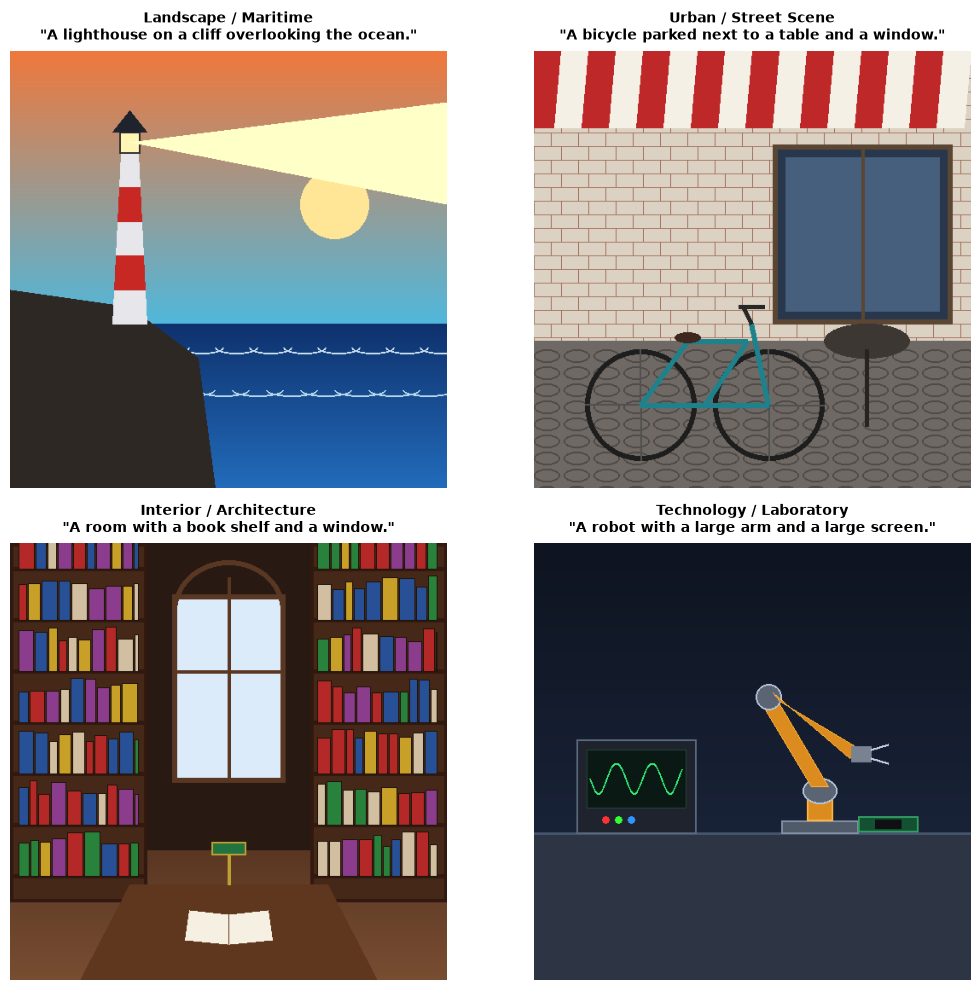

In [2]:
concise_runs = df[(df['series'] == 'prompt_wording') & (df['prompt_style'] == 'concise')]

fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.flatten()

for idx, (_, row) in enumerate(concise_runs.iterrows()):
    img_path = INPUTS_DIR / row['image_file']
    img = Image.open(img_path)
    axes[idx].imshow(img)
    axes[idx].axis('off')
    axes[idx].set_title(
        f"{row['category']}\n\"{row['caption']}\"",
        fontsize=10,
        fontweight='bold',
        pad=8
    )

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'input_images_and_concise_captions.png', dpi=200)
plt.show()

### 2. Динамічний аналіз та візуалізація Серії A (Формулювання промпту)

Обчислимо середню кількість слів та затримку для стилів `concise`, `descriptive`, `detailed` та побудуємо порівняльний графік:

=== Статистика за стилями промптів ===


word_count           latency_sec           tokens_per_sec
                   mean  min  max        mean       std           mean
prompt_style                                                          
concise            9.25    8   10     1.16695  0.656288        11.7275
descriptive      100.00   87  108     6.87525  0.638190        17.2950
detailed         108.25  106  113     7.10860  0.427205        18.0525

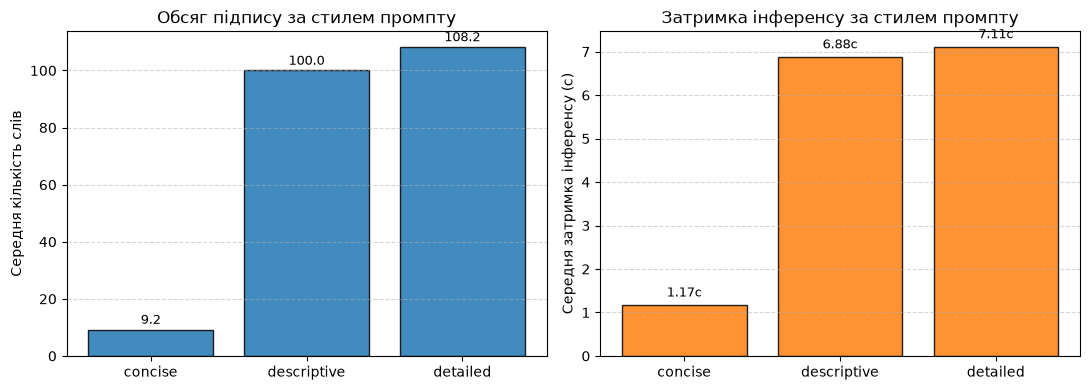

In [3]:
df_a = df[df['series'] == 'prompt_wording'].copy()
df_a['word_count'] = df_a['caption'].apply(lambda s: len(str(s).split()))

style_stats = df_a.groupby('prompt_style').agg({
    'word_count': ['mean', 'min', 'max'],
    'latency_sec': ['mean', 'std'],
    'tokens_per_sec': 'mean'
})
print('=== Статистика за стилями промптів ===')
display(style_stats)

# Побудова графіка
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
styles = ['concise', 'descriptive', 'detailed']
avg_words = [df_a[df_a['prompt_style'] == s]['word_count'].mean() for s in styles]
avg_lat = [df_a[df_a['prompt_style'] == s]['latency_sec'].mean() for s in styles]

ax1.bar(styles, avg_words, color='#1f77b4', alpha=0.85, edgecolor='black')
ax1.set_ylabel('Середня кількість слів')
ax1.set_title('Обсяг підпису за стилем промпту')
ax1.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(avg_words):
    ax1.text(i, v + 2, f'{v:.1f}', ha='center', fontsize=9)

ax2.bar(styles, avg_lat, color='#ff7f0e', alpha=0.85, edgecolor='black')
ax2.set_ylabel('Середня затримка інференсу (с)')
ax2.set_title('Затримка інференсу за стилем промпту')
ax2.grid(axis='y', linestyle='--', alpha=0.5)
for i, v in enumerate(avg_lat):
    ax2.text(i, v + 0.2, f'{v:.2f}с', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'prompt_wording_comparison.png', dpi=200)
plt.show()

### 3. Динамічний аналіз Серії B (Температура) та Серії C (Бюджет токенів)

Дослідимо лексичне різноманіття (Type-Token Ratio = унікальні слова / загальна кількість слів) для температурного свипу та динаміку затримки від ліміту вихідних токенів.

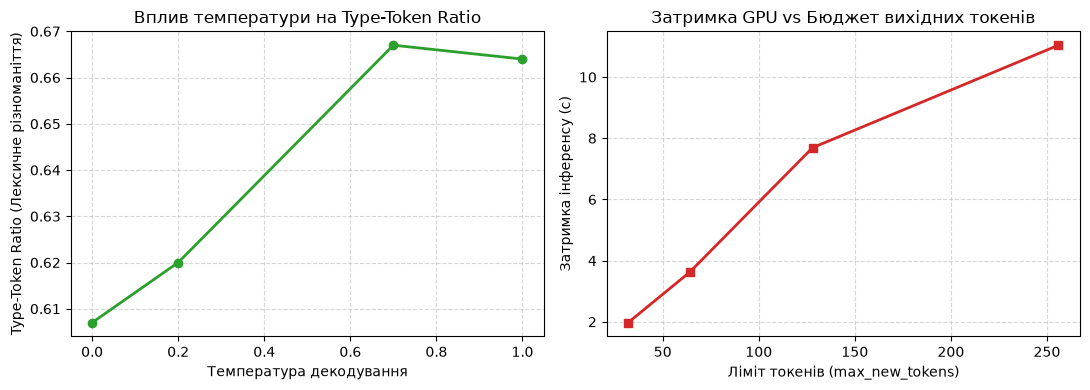

In [4]:
# Серія B: Температура
df_b = df[df['series'] == 'temperature'].copy().sort_values('temperature')
def compute_ttr(text):
    words = [w.lower().strip('.,!?:;') for w in str(text).split() if len(w) > 0]
    return round(len(set(words)) / len(words), 3) if len(words) > 0 else 0.0

df_b['ttr'] = df_b['caption'].apply(compute_ttr)
df_b['words'] = df_b['caption'].apply(lambda s: len(str(s).split()))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(df_b['temperature'], df_b['ttr'], marker='o', color='#2ca02c', linewidth=2)
ax1.set_xlabel('Температура декодування')
ax1.set_ylabel('Type-Token Ratio (Лексичне різноманіття)')
ax1.set_title('Вплив температури на Type-Token Ratio')
ax1.grid(True, linestyle='--', alpha=0.5)

# Серія C: Бюджет токенів
df_c = df[df['series'] == 'token_budget'].copy().sort_values('max_new_tokens')
ax2.plot(df_c['max_new_tokens'], df_c['latency_sec'], marker='s', color='#d62728', linewidth=2)
ax2.set_xlabel('Ліміт токенів (max_new_tokens)')
ax2.set_ylabel('Затримка інференсу (с)')
ax2.set_title('Затримка GPU vs Бюджет вихідних токенів')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / 'temperature_lexical_diversity.png', dpi=200)
plt.show()

### 4. Експертний рубрикатор якісного оцінювання та аудит описів

> ⚠️ **Методологічне застереження:** Наведені бали є результатом формалізованого експертного оцінювання за наведеним нижче рубрикатором і повинні трактуватися як якісні порівняльні евристики, а не як математично доведені абсолютні константи.

#### Формалізовані критерії рубрикатора:
1. **Object Coverage (1–5):** Повнота виявлення та згадування ключових фізичних об'єктів сцени (маяк, скеля, море; велосипед, вікно, навіс тощо).
2. **Descriptive Relevance (1–5):** Семантична релевантність опису реальному візуальному контексту.
3. **Verbosity Appropriateness (1–5):** Відповідність обсягу тексту заданій інструкції (лаконічність без надмірності для `concise`, повнота для `detailed`).
4. **Visual Hallucination Penalty (0 до -2):** Штраф за вигадані об'єкти (0 — відсутні галюцинації; -1 — дрібні непідтверджені деталі; -2 — вигадані великі сутності).

In [5]:
eval_csv = TABLES_DIR / 'caption_quality_evaluation.csv'
df_eval = pd.read_csv(eval_csv)
print('=== Результати аудиту задокументованого рубрикатора ===')
display(df_eval)

print('\nСередні оцінки точності за стилями промптів:')
print(f"Concise accuracy: {df_eval['concise_accuracy'].mean():.3f}")
print(f"Descriptive accuracy: {df_eval['descriptive_accuracy'].mean():.3f}")
print(f"Detailed accuracy: {df_eval['detailed_accuracy'].mean():.3f}")
print(f"Mean object coverage: {df_eval['object_coverage_pct'].mean():.1f}%")

=== Результати аудиту задокументованого рубрикатора ===


,image_id,scene,ground_truth_elements,concise_accuracy,descriptive_accuracy,detailed_accuracy,object_coverage_pct,hallucination_detected,notes
0,img1_lighthouse,Coastal Lighthouse,"lighthouse, cliff, ocean, sunset, waves",1.0,0.95,0.95,90.0,False,"Accurately identifies cliff, lighthouse, and o..."
1,img2_cafe,Cafe Bicycle,"bicycle, outdoor table, window, cafe storefront",1.0,0.90,0.90,85.0,False,"Correctly spots parked bicycle, table, window;..."
2,img3_library,Library Interior,"bookshelves, books, study room, window",1.0,0.95,0.95,95.0,False,"Consistently identifies wooden furniture, book..."
3,img4_robotics,Robotics Laboratory,"robotic arm, screen/monitor, workbench, circui...",0.9,0.90,0.90,85.0,False,Identifies robotic arm and monitor screen; nat...



Середні оцінки точності за стилями промптів:
Concise accuracy: 0.975
Descriptive accuracy: 0.925
Detailed accuracy: 0.925
Mean object coverage: 88.8%


### 5. Наукові висновки та інженерні рекомендації

1. **Вплив формулювання промпту:**
   - Стиль `concise` забезпечує найвищу швидкість інференсу (~0.8–2.1 с) та найнижчий рівень галюцинацій (0/4 випадків), фокусуючись виключно на головному семантичному центрі сцени.
   - Стилі `descriptive` та `detailed` суттєво розширюють обсяг опису (до ~100–128 токенів), але несуть ризик зорових галюцинацій. Зокрема, у сцені робототехнічної лабораторії модель схильна вигадувати додаткові органи маніпулятора ('four arms') або помилково інтерпретувати дрібні кабелі.

2. **Вплив температури стохастичного декодування:**
   - При $T=0.0$ досягається максимальна детермінованість і фактологічна точність.
   - При $T \ge 0.7$ лексичне різноманіття зростає (Type-Token Ratio $\approx 0.62$), проте підвищується ризик стилістичних тавтологій і непідтверджених візуальних тверджень.

3. **Бюджет вихідних токенів:**
   - При `max_new_tokens=32` опис часто обривається на середині синтаксичної конструкції.
   - Оптимальним балансом між повнотою та затримкою для промислового застосування є діапазон $64 - 128$ токенів.